# PALLAS surrogate models 

## 1. Data loading

In [1]:
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

# Relative to your notebook's current working directory.
# Replace with an absolute path if needed.
BASE = Path(
    "../artifact-hackathon-2026/challenges/surrogate-models/data_surrogated"
).resolve()

# Search for the full pack, then the sample.
CANDIDATES = [
    Path(os.environ["PALLAS_PACK"]).expanduser()
    if os.environ.get("PALLAS_PACK") else None,
    BASE / "pallas_hackathon_data",
    BASE,
    BASE / "sample",
]

PACK = next(
    (
        candidate
        for candidate in CANDIDATES
        if candidate is not None
        and (candidate / "campaign_A.parquet").is_file()
    ),
    None,
)

if PACK is None:
    raise FileNotFoundError(
        f"No data pack found under {BASE}\n"
        f"Current working directory: {Path.cwd()}\n"
        "Set BASE to the absolute path of your data_surrogated directory."
    )

# Validate the files and columns against the schema.
schema_path = BASE / "ontologies" / "pack_schema.json"

with schema_path.open(encoding="utf-8") as fh:
    SCHEMA = json.load(fh)

for name, spec in SCHEMA["files"].items():
    path = PACK / name

    if not path.is_file():
        raise FileNotFoundError(f"Required file is missing: {path}")

    if name.endswith(".parquet"):
        available = set(pq.ParquetFile(path).schema_arrow.names)
        missing = set(spec["columns"]) - available

        if missing:
            raise ValueError(f"{name} lacks columns: {sorted(missing)}")

# Load only scalar columns, excluding spectra and density curves.
SCALARS = [
    "scan", "config", "p_1", "a_0", "c_N2", "x_of",
    "P_max", "cN2_max", "L_inj", "dip_frac",
    "E_med_MeV", "E_mean_MeV", "dE_mad", "dE_std",
    "q_pC", "q_end", "i_peak",
    "sigma_z", "sigma_y", "n_emit_x", "n_emit_y",
    "div_rms", "injected",
]

def load(name):
    path = PACK / f"{name}.parquet"
    available = pq.ParquetFile(path).schema_arrow.names
    columns = [column for column in SCALARS if column in available]
    return pd.read_parquet(path, columns=columns)

A = load("campaign_A")
B = load("campaign_B")
grid = np.load(PACK / "common_energy_grid_MeV.npy")

print(f"Data folder: {PACK}")
print(f"Campaign A: {len(A):,} simulations")
print(f"Campaign B: {len(B):,} simulations")

if PACK == BASE / "sample":
    print("Using the 10% sample.")

display(A.head())
display(B.head())

Data folder: /home/qou/AI_Hackathon/artifact-hackathon-2026/challenges/surrogate-models/data_surrogated/pallas_hackathon_data
Campaign A: 13,073 simulations
Campaign B: 5,286 simulations


,scan,config,p_1,a_0,c_N2,x_of,E_med_MeV,E_mean_MeV,dE_mad,dE_std,q_pC,q_end,i_peak,sigma_z,sigma_y,n_emit_x,n_emit_y,div_rms,injected
0,random,11,51.967970,1.328588,0.031888,740.016691,176.890297,182.658976,0.062651,0.108350,150.826672,1.508267e-10,7701.320948,0.000002,0.000002,0.000001,0.000004,0.005604,True
1,random,101,81.175615,1.278433,0.041408,914.823751,117.437183,113.083162,0.187095,0.234163,272.069986,2.720700e-10,12166.720834,0.000003,0.000004,0.000004,0.000007,0.011650,True
2,random,1001,33.709236,1.100172,0.061323,731.207475,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
3,random,1002,68.886697,1.195013,0.072505,560.282091,89.495034,89.469613,0.372771,0.455383,270.789954,2.707900e-10,9867.215564,0.000005,0.000005,0.000006,0.000011,0.016154,True
4,random,1003,97.236441,1.116539,0.103158,790.421058,115.507544,101.976347,0.207592,0.398384,194.815044,1.948150e-10,8616.965730,0.000006,0.000008,0.000016,0.000020,0.017338,True


,config,a_0,x_of,P_max,cN2_max,L_inj,dip_frac,E_med_MeV,E_mean_MeV,dE_mad,dE_std,q_pC,q_end,i_peak,sigma_z,sigma_y,n_emit_x,n_emit_y,div_rms,injected
0,1065,1.25,1492.414048,4029.926805,0.071580,0.400605,0.118237,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1098,1.25,1711.534893,4266.843694,0.066978,0.566518,0.378512,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1093,1.25,1643.475844,4111.595115,0.096340,0.438924,0.333832,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1011,1.25,1546.986129,4956.362657,0.076182,0.560563,0.158826,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
4,100,1.25,1632.619931,4058.131647,0.106004,0.511939,0.294766,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False


## Objective Easy: 1

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor

A_clean = A.dropna()

inputs = ["E_med_MeV", "dE_mad", "q_end", "i_peak", "n_emit_x", "sigma_z", "sigma_y", "div_rms", "x_of"]
outputs = ["p_1", "a_0", "c_N2"]


#Divide A_clean in train and test data:
train, test = train_test_split(A_clean, test_size=0.2, random_state=0)


#Divide train and test dataframes in input/output dataframes
x_train, y_train = train[inputs], train[outputs]
x_test, y_test = test[inputs], test[outputs] 

In [3]:
#We need to scale the input training data columns so that all have similar values 
scaler_inputs = StandardScaler()

#Fit scaler to training input data:
scaler_inputs.fit(x_train)

#Apply the fitted scaler to the training and testing data
x_train_scaled = scaler_inputs.transform(x_train)
x_test_scaled = scaler_inputs.transform(x_test)

#We do the same for output data:
scaler_outputs = StandardScaler()

scaler_outputs.fit(y_train)
y_train_scaled = scaler_outputs.transform(y_train)
y_test_scaled = scaler_outputs.transform(y_test)

In [4]:
#We can first try with a linear regression model:
lin_reg = LinearRegression().fit(x_train_scaled, y_train_scaled)
R_squared = lin_reg.score(x_test_scaled, y_test_scaled)
print(f'R2 for linear regression is {R_squared}')

R2 for linear regression is 0.655507718572725


In [5]:
#To improve the previous prediction model, we try to use a simple random forest model to fit the training data:
from sklearn.ensemble import RandomForestRegressor

regr = RandomForestRegressor(max_depth=1000, random_state=0)
regr.fit(x_train_scaled, y_train_scaled)

#We now calculate R^2 in test data
R_squared = regr.score(x_test_scaled, y_test_scaled)
print(f'R2 for random forest is {R_squared}')

R2 for random forest is 0.9435978173225679


## Objective Easy: 2

In [6]:
B_clean = B.dropna()
#print(B_clean)

inputs_B = ["P_max", "cN2_max", "L_inj", "dip_frac", "x_of"]
outputs_B = ["E_med_MeV", "dE_mad", "q_end"]

#Divide B_clean in train and test data:
train, test = train_test_split(B_clean, test_size=0.2, random_state=0)


#Divide train and test dataframes in input/output dataframes
x_train, y_train = train[inputs_B], train[outputs_B]
x_test, y_test = test[inputs_B], test[outputs_B] 

In [7]:
#We need to scale the input training data columns so that all have similar values 
scaler_inputs = StandardScaler()

#Fit scaler to training input data:
scaler_inputs.fit(x_train)

#Apply the fitted scaler to the training and testing data
x_train_scaled = scaler_inputs.transform(x_train)
x_test_scaled = scaler_inputs.transform(x_test)

#We do the same for output data:
scaler_outputs = StandardScaler()

scaler_outputs.fit(y_train)
y_train_scaled = scaler_outputs.transform(y_train)
y_test_scaled = scaler_outputs.transform(y_test)

In [8]:
#We directly try to use a simple random forest model to fit the training data:
from sklearn.ensemble import RandomForestRegressor

regr = RandomForestRegressor(max_depth=1000, random_state=0)
regr.fit(x_train_scaled, y_train_scaled)

#We now calculate R^2 in test data
R_squared = regr.score(x_test_scaled, y_test_scaled)
print(f'R2 for random forest is {R_squared}')

R2 for random forest is 0.9187330929014789


In [9]:
#Separate scores per output variable:
from sklearn.metrics import r2_score

y_pred = regr.predict(x_test_scaled)
r2_scores = r2_score(y_test_scaled, y_pred, multioutput='raw_values')
for i, k in enumerate(outputs_B):
    print(f'{k} r2 score: {r2_scores[i]}')

E_med_MeV r2 score: 0.9579829494478129
dE_mad r2 score: 0.8466755003008684
q_end r2 score: 0.9515408289557552


## Try fancier models

In [10]:
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.multioutput import MultiOutputRegressor
from sklearn.multioutput import RegressorChain
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import (ExtraTreesRegressor,GradientBoostingRegressor,HistGradientBoostingRegressor)
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

model = make_pipeline( # PolynomialFeatures(degree=3, include_bias=False),
    StandardScaler(),
    # LinearRegression(),
    # RandomForestRegressor(n_estimators=1000, random_state=42),
    # ExtraTreesRegressor(n_estimators=200, n_jobs=-1, random_state=42),
    # MultiOutputRegressor(GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=42),n_jobs=-1,),
    # RegressorChain(GradientBoostingRegressor(random_state=42), order=[0, 1, 2]),
    # RegressorChain(HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=42), order=[0, 1, 2]),
    # RegressorChain(SVR(kernel="rbf", C=1.0, epsilon=0.1) , order=[0, 1, 2]),

    # Ridge(alpha=1.0)                      # L2: shrinks coefficients, stable with many correlated features
    # Lasso(alpha=0.01, max_iter=10000)     # L1: zeroes out useless polynomial terms (feature selection)
    # ElasticNet(alpha=0.01, l1_ratio=0.5, max_iter=10000)  # mix of both
    # KNeighborsRegressor(n_neighbors=5)             # simple, scaling required
    MLPRegressor(hidden_layer_sizes=(128, 64, 28), max_iter=1000, random_state=42),  # small neural net
)

In [11]:
model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(128, 64, 28),
        #activation = 'relu',
        max_iter=1000,
        random_state=42
    )
)

# The pipeline scales inputs internally.
# Outputs use your previously fitted scaler_outputs.
model.fit(x_train, y_train_scaled)

y_pred_scaled = model.predict(x_test)

scores = r2_score(
    y_test_scaled, y_pred_scaled, multioutput="raw_values"
)

for name, score in zip(outputs_B, scores):
    print(f"{name} R²: {score:.4f}")

E_med_MeV R²: 0.9958
dE_mad R²: 0.9733
q_end R²: 0.9964


## Objective Easy: 3

In [12]:
A_clean = A.dropna()

inputs_A = ["p_1", "a_0", "c_N2", 'x_of']
outputs_A = ["E_med_MeV", "dE_mad", "q_end"]


#Divide A_clean in train and test data:
train, test = train_test_split(A_clean, test_size=0.2, random_state=0)


#Divide train and test dataframes in input/output dataframes
x_train, y_train = train[inputs_A], train[outputs_A]
x_test, y_test = test[inputs_A], test[outputs_A] 

In [13]:
#We need to scale the input training data columns so that all have similar values 
scaler_inputs = StandardScaler()

#Fit scaler to training input data:
scaler_inputs.fit(x_train)

#Apply the fitted scaler to the training and testing data
x_train_scaled = scaler_inputs.transform(x_train)
x_test_scaled = scaler_inputs.transform(x_test)

#We do the same for output data:
scaler_outputs = StandardScaler()

scaler_outputs.fit(y_train)
y_train_scaled = scaler_outputs.transform(y_train)
y_test_scaled = scaler_outputs.transform(y_test)

In [14]:
regr = RandomForestRegressor(max_depth=1000, random_state=0)
regr.fit(x_train_scaled, y_train_scaled)

#We now calculate R^2 in test data
R_squared = regr.score(x_test_scaled, y_test_scaled)
print(f'R2 for random forest is {R_squared}')

y_pred_scaled = regr.predict(x_test_scaled)

scores = r2_score(
    y_test_scaled, y_pred_scaled, multioutput="raw_values"
)

for name, score in zip(outputs_A, scores):
    print(f"{name} R²: {score:.4f}")

R2 for random forest is 0.9707845134044546
E_med_MeV R²: 0.9864
dE_mad R²: 0.9427
q_end R²: 0.9832


In [15]:
model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(128, 256, 128, 64, 28),
        #activation = 'relu',
        max_iter=1000,
        random_state=42
    )
)

# The pipeline scales inputs internally.
# Outputs use your previously fitted scaler_outputs.
model.fit(x_train, y_train_scaled)

y_pred_scaled = model.predict(x_test)

scores = r2_score(
    y_test_scaled, y_pred_scaled, multioutput="raw_values"
)

R2_score = model.score(x_test, y_test_scaled)
print(f'R2 for MLP regressor is {R2_score}')

for name, score in zip(outputs_A, scores):
    print(f"{name} R²: {score:.4f}")

R2 for MLP regressor is 0.993735692651172
E_med_MeV R²: 0.9981
dE_mad R²: 0.9855
q_end R²: 0.9977


## Objective Easy: 4

In [16]:
df_trajectories = pd.read_parquet(f"{PACK}/campaign_B_trajectories.parquet")

#filter by cfg 
df_trajectories_cfg = df_trajectories["config"].unique()

#for i in range(len(df_trajectories_cfg)):
df_trajectories_cfg=0
traj_cfg = df_trajectories.loc[df_trajectories["config"] == df_trajectories["config"].unique()[0]].sort_values("z_mm")
z_inj = traj_cfg["z_mm"].to_list()[0]
print(z_inj)

2.015054941177368


In [17]:
#Filter the dataset to only include the z positions inside the plasma:
L_plasma = 3.2
z_filter  = z_inj + L_plasma

In [18]:
df_trajectories_clean = df_trajectories.dropna()
print(df_trajectories_clean.shape[0])
df_trajectories_clean = df_trajectories_clean[df_trajectories_clean["z_mm"]<=z_filter]
print(df_trajectories_clean.shape[0])


inputs_B = ["P_max", "cN2_max", "L_inj", "dip_frac", "x_of", 'z_mm']
outputs_B = ["E_MeV", "q_pC", "dE_pct", "emit_um", "div_mrad", "sigz_um"]

#Divide B_clean in train and test data:
train, test = train_test_split(df_trajectories_clean, test_size=0.2, random_state=0)


#Divide train and test dataframes in input/output dataframes
x_train, y_train = train[inputs_B], train[outputs_B]
x_test, y_test = test[inputs_B], test[outputs_B] 

322615
205560


In [19]:
#We need to scale the input training data columns so that all have similar values 
scaler_inputs = StandardScaler()

#Fit scaler to training input data:
scaler_inputs.fit(x_train)

#Apply the fitted scaler to the training and testing data
x_train_scaled = scaler_inputs.transform(x_train)
x_test_scaled = scaler_inputs.transform(x_test)

#We do the same for output data:
scaler_outputs = StandardScaler()

scaler_outputs.fit(y_train)
y_train_scaled = scaler_outputs.transform(y_train)
y_test_scaled = scaler_outputs.transform(y_test)

In [20]:
#We can first try with a linear regression model:
lin_reg = LinearRegression().fit(x_train_scaled, y_train_scaled)
R_squared = lin_reg.score(x_test_scaled, y_test_scaled)
print(f'R2 for linear regression is {R_squared}')

R2 for linear regression is 0.6216245889663696


In [21]:
#We directly try to use a simple random forest model to fit the training data:
from sklearn.ensemble import RandomForestRegressor

regr = RandomForestRegressor(max_depth=1000, random_state=0)
regr.fit(x_train_scaled, y_train_scaled)

#We now calculate R^2 in test data
R_squared = regr.score(x_test_scaled, y_test_scaled)
print(f'R2 for random forest is {R_squared}')

R2 for random forest is 0.9974414782039874


In [22]:
model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(128, 64, 28),
        #activation = 'relu',
        max_iter=1000,
        random_state=42
    )
)

# The pipeline scales inputs internally.
# Outputs use your previously fitted scaler_outputs.
model.fit(x_train, y_train_scaled)

R2_score = model.score(x_test, y_test_scaled)
print(f'R2 for MLP regressor is {R2_score}')

y_pred_scaled = model.predict(x_test)

scores = r2_score(
    y_test_scaled, y_pred_scaled, multioutput="raw_values"
)

for name, score in zip(outputs_B, scores):
    print(f"{name} R²: {score:.4f}")

R2 for MLP regressor is 0.9919015765190125
E_MeV R²: 0.9976
q_pC R²: 0.9973
dE_pct R²: 0.9859
emit_um R²: 0.9914
div_mrad R²: 0.9935
sigz_um R²: 0.9856


## Objective Medium: 1

In [23]:
model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(128, 64, 28),
        #activation = 'relu',
        max_iter=1000,
        random_state=42
    )
)

# The pipeline scales inputs internally.
# Outputs use your previously fitted scaler_outputs.
model.fit(x_train, y_train_scaled)

R2_score = model.score(x_test, y_test_scaled)
print(f'R2 for MLP regressor is {R2_score}')

y_pred_scaled = model.predict(x_test)

scores = r2_score(
    y_test_scaled, y_pred_scaled, multioutput="raw_values"
)

for name, score in zip(outputs_B, scores):
    print(f"{name} R²: {score:.4f}")

R2 for MLP regressor is 0.9919015765190125
E_MeV R²: 0.9976
q_pC R²: 0.9973
dE_pct R²: 0.9859
emit_um R²: 0.9914
div_mrad R²: 0.9935
sigz_um R²: 0.9856


## Objective Medium: 2

In [24]:
B_clean = B.dropna()
#print(B_clean)

inputs_B = ["E_med_MeV", "dE_mad", "q_end", "i_peak", "n_emit_x", "sigma_z", "sigma_y", "div_rms", "x_of"]#["E_med_MeV", "dE_mad", "q_end", "x_of"]
outputs_B = ["P_max", "cN2_max", "L_inj", "dip_frac"]

#Divide B_clean in train and test data:
train, test = train_test_split(B_clean, test_size=0.2, random_state=0)


#Divide train and test dataframes in input/output dataframes
x_train, y_train = train[inputs_B], train[outputs_B]
x_test, y_test = test[inputs_B], test[outputs_B] 

In [25]:
#We need to scale the input training data columns so that all have similar values 
scaler_inputs = StandardScaler()

#Fit scaler to training input data:
scaler_inputs.fit(x_train)

#Apply the fitted scaler to the training and testing data
x_train_scaled = scaler_inputs.transform(x_train)
x_test_scaled = scaler_inputs.transform(x_test)

#We do the same for output data:
scaler_outputs = StandardScaler()

scaler_outputs.fit(y_train)
y_train_scaled = scaler_outputs.transform(y_train)
y_test_scaled = scaler_outputs.transform(y_test)

In [26]:
model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(128, 64, 28),
        #activation = 'relu',
        max_iter=1000,
        random_state=42
    )
)

# The pipeline scales inputs internally.
# Outputs use your previously fitted scaler_outputs.
model.fit(x_train, y_train_scaled)

R2_score = model.score(x_test, y_test_scaled)
print(f'R2 for MLP regressor is {R2_score}')

y_pred_scaled = model.predict(x_test)

scores = r2_score(
    y_test_scaled, y_pred_scaled, multioutput="raw_values"
)

for name, score in zip(outputs_B, scores):
    print(f"{name} R²: {score:.4f}")

R2 for MLP regressor is 0.8811123091177648
P_max R²: 0.9697
cN2_max R²: 0.9461
L_inj R²: 0.9296
dip_frac R²: 0.6791


### Build a surrogated model using neural network to predict medium: 2

In [28]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

class NeuralNetwork(nn.Module):
    def __init__(self, input_size, output_size):
        super(NeuralNetwork, self).__init__()

        # Define the first hidden layer 
        self.hidden1 = nn.Linear(input_size, 128)
        # Define the second and third hidden layers 
        self.hidden2 = nn.Linear(128, 64)
        self.hidden3 = nn.Linear(64, 32)      
        # Define the output layer (64 neurons to output_size)
        self.output = nn.Linear(32, output_size)

    # Define the forward pass
    def forward(self, x):
        # Apply the  ReLU activations
        x = F.relu(self.hidden1(x))
        x = F.relu(self.hidden2(x))
        x = F.relu(self.hidden3(x))
        x = self.output(x)
        
        return x
    


In [29]:
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X_tensor = torch.tensor(x_train_scaled, dtype=torch.float32)
Y_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)

input_size = 9  
output_size = 4 

train_loader = DataLoader(
    TensorDataset(X_tensor, Y_tensor),
    batch_size=input_size,
    shuffle=True,
)

model = NeuralNetwork(input_size=input_size, output_size=output_size).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)


# Training
n_epochs = 300
loss_history = []

for epoch in range(n_epochs):
    model.train()
    total_loss = 0.0

    for x_batch, y_batch in train_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        predictions = model(x_batch)
        loss = criterion(predictions, y_batch)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x_batch.size(0)

    epoch_loss = total_loss / len(train_loader.dataset)
    loss_history.append(epoch_loss)

    if epoch == 0 or (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1:3d}/{n_epochs}: MSE = {epoch_loss:.6f}")

Epoch   1/300: MSE = 0.544585
Epoch  10/300: MSE = 0.227465
Epoch  20/300: MSE = 0.144867
Epoch  30/300: MSE = 0.115600
Epoch  40/300: MSE = 0.099597
Epoch  50/300: MSE = 0.088711
Epoch  60/300: MSE = 0.081060
Epoch  70/300: MSE = 0.075022
Epoch  80/300: MSE = 0.072790
Epoch  90/300: MSE = 0.065562
Epoch 100/300: MSE = 0.064661
Epoch 110/300: MSE = 0.059983
Epoch 120/300: MSE = 0.058862
Epoch 130/300: MSE = 0.057092
Epoch 140/300: MSE = 0.053518
Epoch 150/300: MSE = 0.053647
Epoch 160/300: MSE = 0.050852
Epoch 170/300: MSE = 0.048076
Epoch 180/300: MSE = 0.045410
Epoch 190/300: MSE = 0.048080
Epoch 200/300: MSE = 0.041910
Epoch 210/300: MSE = 0.041046
Epoch 220/300: MSE = 0.041775
Epoch 230/300: MSE = 0.038917
Epoch 240/300: MSE = 0.039344
Epoch 250/300: MSE = 0.037463
Epoch 260/300: MSE = 0.035932
Epoch 270/300: MSE = 0.034110
Epoch 280/300: MSE = 0.034422
Epoch 290/300: MSE = 0.034390
Epoch 300/300: MSE = 0.033409


In [30]:
model.eval()
with torch.no_grad():
    y_pred_scaled = model(
        torch.tensor(
            x_test_scaled,
            dtype=torch.float32,
            device=device,
        )
    ).cpu().numpy()

In [31]:
y_pred = scaler_outputs.inverse_transform(y_pred_scaled)

r2_per_output = r2_score(
    np.asarray(y_test),
    y_pred,
    multioutput="raw_values",
)

r2_mean = np.mean(r2_per_output)

for i, r2 in enumerate(r2_per_output):
    print(f"Output {i + 1}: R² = {r2:.4f}")

#r2_mean = r2_score(y_test, y_pred, multioutput="uniform_average")
    
print(f"Mean R²: {r2_mean:.4f}")


# y_tensor = torch.tensor(np.asarray(y_train_scaled), dtype=torch.long)
# y_tensor

Output 1: R² = 0.9745
Output 2: R² = 0.9453
Output 3: R² = 0.9351
Output 4: R² = 0.6852
Mean R²: 0.8850


/home/qou/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


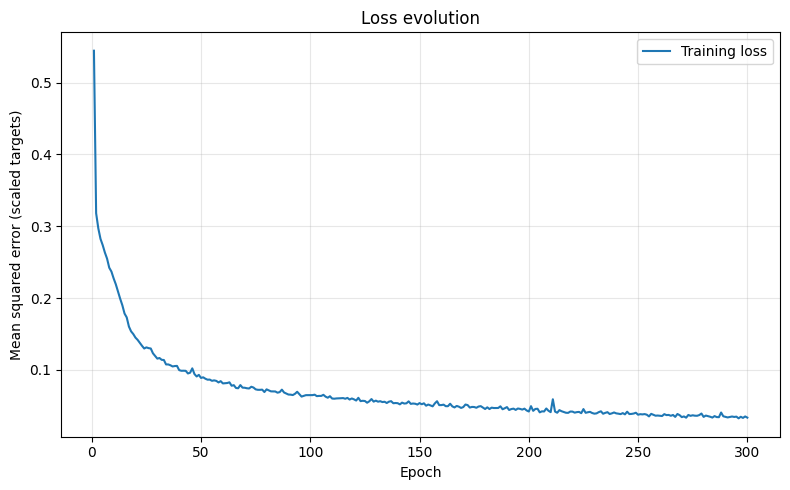

In [32]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    range(1, len(loss_history) + 1),
    loss_history,
    label="Training loss",
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Mean squared error (scaled targets)")
ax.set_title("Loss evolution")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

## Objective Medium: 3

In [ ]:
df_moments = pd.read_parquet(f"{PACK}/campaign_B_moments.parquet")
df_moments
print(list(df_moments))

In [ ]:
df_moments_clean = df_moments.dropna().copy()
print(df_moments_clean.shape[0])

df_moments_clean["sigma_zeta"] = np.sqrt(df_moments_clean['cov_00'])
df_moments_clean["sigma_y"] = np.sqrt(df_moments_clean['cov_11'])
df_moments_clean["sigma_z"] = np.sqrt(df_moments_clean['cov_22'])
df_moments_clean["sigma_ux"] = np.sqrt(df_moments_clean['cov_33'])
df_moments_clean["sigma_uy"] = np.sqrt(df_moments_clean['cov_44'])
df_moments_clean["sigma_uz"] = np.sqrt(df_moments_clean['cov_55'])





inputs_B = ["P_max", "cN2_max", "L_inj", "dip_frac", "x_of", "plane_mm"]
outputs_B = ["mean_zeta_um", "mean_y_um", "mean_z_um", "mean_ux", "mean_uy", "mean_uz", "sigma_zeta", "sigma_y", "sigma_z", "sigma_ux", "sigma_uy", "sigma_uz", "q_tot_pC"]

#Divide B_clean in train and test data:
train, test = train_test_split(df_moments_clean, test_size=0.2, random_state=0)


#Divide train and test dataframes in input/output dataframes
x_train, y_train = train[inputs_B], train[outputs_B]
x_test, y_test = test[inputs_B], test[outputs_B] 

In [ ]:
#We need to scale the input training data columns so that all have similar values 
scaler_inputs = StandardScaler()

#Fit scaler to training input data:
scaler_inputs.fit(x_train)

#Apply the fitted scaler to the training and testing data
x_train_scaled = scaler_inputs.transform(x_train)
x_test_scaled = scaler_inputs.transform(x_test)

#We do the same for output data:
scaler_outputs = StandardScaler()

scaler_outputs.fit(y_train)
y_train_scaled = scaler_outputs.transform(y_train)
y_test_scaled = scaler_outputs.transform(y_test)

In [ ]:
# Use the same model as in objective medium 2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X_tensor = torch.tensor(x_train_scaled, dtype=torch.float32)
Y_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)

train_loader = DataLoader(
    TensorDataset(X_tensor, Y_tensor),
    batch_size=64,
    shuffle=True,
)

model = NeuralNetwork(input_size=6, output_size=13).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)



# Training
n_epochs = 300
loss_history = []

for epoch in range(n_epochs):
    model.train()
    total_loss = 0.0

    for x_batch, y_batch in train_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        predictions = model(x_batch)
        loss = criterion(predictions, y_batch)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x_batch.size(0)

    epoch_loss = total_loss / len(train_loader.dataset)
    loss_history.append(epoch_loss)

    if epoch == 0 or (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1:3d}/{n_epochs}: MSE = {epoch_loss:.6f}")

In [ ]:
model.eval()
with torch.no_grad():
    y_pred_scaled = model(
        torch.tensor(
            x_test_scaled,
            dtype=torch.float32,
            device=device,
        )
    ).cpu().numpy()

In [ ]:
y_pred = scaler_outputs.inverse_transform(y_pred_scaled)

r2_per_output = r2_score(
    np.asarray(y_test),
    y_pred,
    multioutput="raw_values",
)

r2_mean = np.mean(r2_per_output)

for i, r2 in enumerate(r2_per_output):
    print(f"Output {i + 1}: R² = {r2:.4f}")

#r2_mean = r2_score(y_test, y_pred, multioutput="uniform_average")
    
print(f"Mean R²: {r2_mean:.4f}")


# y_tensor = torch.tensor(np.asarray(y_train_scaled), dtype=torch.long)
# y_tensor

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    range(1, len(loss_history) + 1),
    loss_history,
    label="Training loss",
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Mean squared error (scaled targets)")
ax.set_title("Loss evolution")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()